
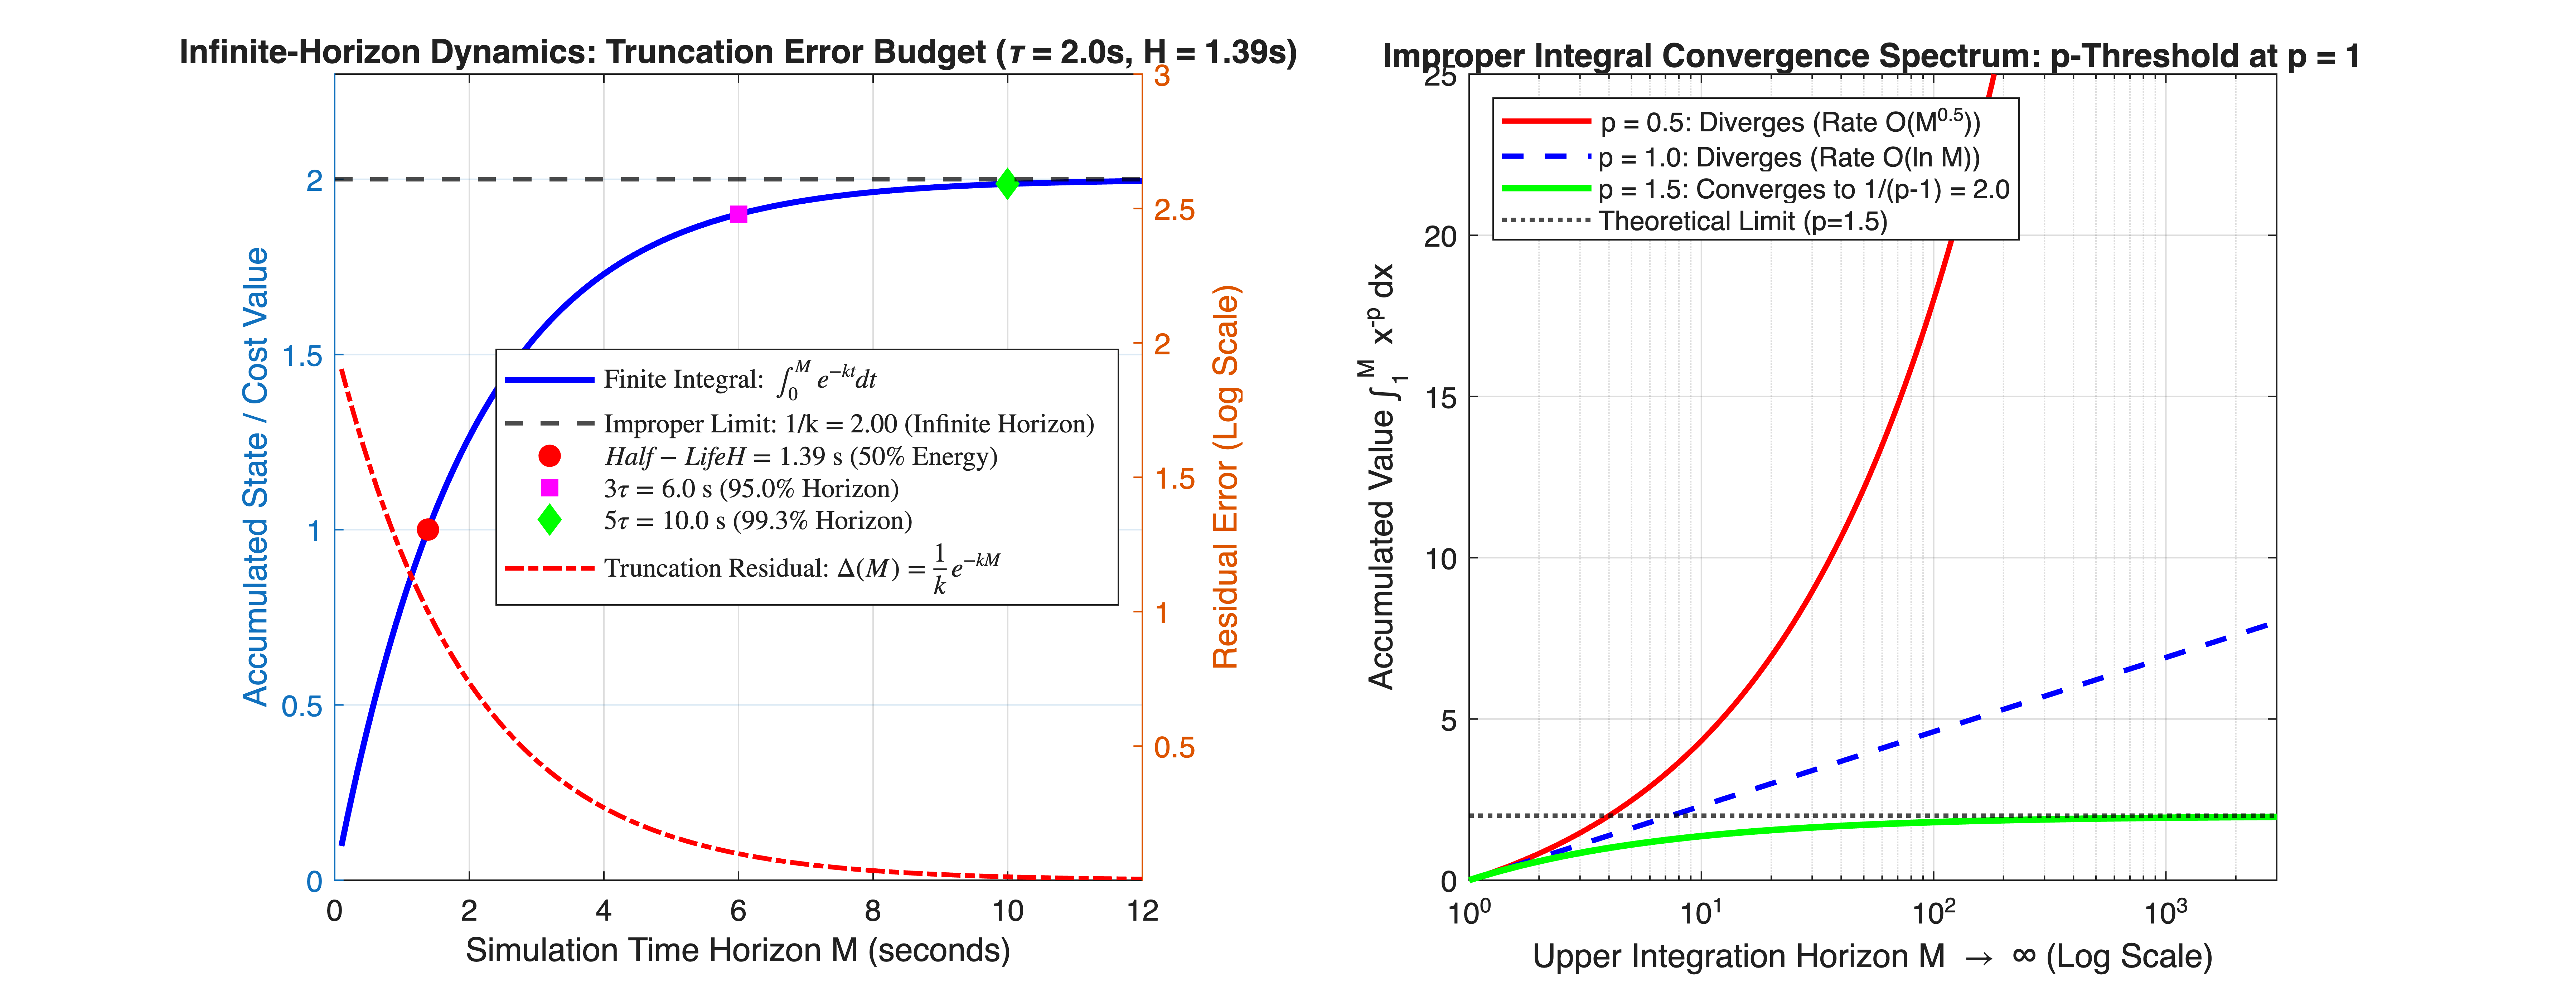

In [1]:
%% MIT 18.01 Lecture 35: Improper Integrals, Stability Horizon & p-Convergence
% Mathematical Tool Application: Used for infinite-horizon LQR cost evaluation,
% BIBO stability verification via impulse response integrability, and finite-time
% simulation truncation error budgeting in continuous dynamical systems.


clear; clc; close all;


%% Part 1: First-Order Decay & Infinite Horizon Truncation Error (Example 1)
% Plant rate factor k = 0.5 s^-1 (Time constant tau = 1/k = 2.0 s)
% Half-life H = ln(2) / k approx 1.3863 s
k_rate = 0.5;
tau_const = 1.0 / k_rate;
H_halflife = log(2.0) / k_rate;


% Infinite horizon analytical value: \int_0^\infty e^{-kt} dt = 1/k
exact_infinite_val = 1.0 / k_rate;


% Finite horizon span M from 0 to 12 seconds
M_span = linspace(0.1, 12.0, 300);
accumulated_finite_val = (1.0 / k_rate) * (1.0 - exp(-k_rate * M_span));
truncation_residual_error = (1.0 / k_rate) * exp(-k_rate * M_span);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
yyaxis left;
plot(M_span, accumulated_finite_val, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 'Finite Integral: $\int_0^M e^{-kt}dt$'); hold on;
yline(exact_infinite_val, 'k--', 'LineWidth', 1.5, ...
    'DisplayName', sprintf('Improper Limit: 1/k = %.2f (Infinite Horizon)', exact_infinite_val));
ylabel('Accumulated State / Cost Value');
ylim([0, exact_infinite_val * 1.15]);


% Mark Half-life and 3*tau checkpoints
plot(H_halflife, (1.0/k_rate)*0.5, 'ro', 'MarkerSize', 7, 'MarkerFaceColor', 'r', ...
    'DisplayName', sprintf('$Half-Life H = %.2f\\text{ s}$ (50\%% Energy)', H_halflife));
plot(3*tau_const, (1.0/k_rate)*(1 - exp(-3)), 'ms', 'MarkerSize', 7, 'MarkerFaceColor', 'm', ...
    'DisplayName', sprintf('$3\\tau = %.1f\\text{ s}$ (95.0\%% Horizon)', 3*tau_const));
plot(5*tau_const, (1.0/k_rate)*(1 - exp(-5)), 'gd', 'MarkerSize', 7, 'MarkerFaceColor', 'g', ...
    'DisplayName', sprintf('$5\\tau = %.1f\\text{ s}$ (99.3\%% Horizon)', 5*tau_const));


yyaxis right;
semilogy(M_span, truncation_residual_error, 'r-.', 'LineWidth', 1.6, ...
    'DisplayName', 'Truncation Residual: $\Delta(M) = \frac{1}{k}e^{-kM}$');
ylabel('Residual Error (Log Scale)');
ylim([1e-3, 3]);


grid on;
xlim([0, 12.0]);
xlabel('Simulation Time Horizon M (seconds)');
title(sprintf('Infinite-Horizon Dynamics: Truncation Error Budget (\\tau = %.1fs, H = %.2fs)', ...
    tau_const, H_halflife));
legend('Location', 'east', 'Interpreter','latex');


%% Part 2: Power Benchmark Convergence Spectrum \int_1^M x^{-p} dx (Examples 4-6)
subplot(1, 2, 2);
x_mesh = logspace(0, 3.5, 400); % Evaluation horizon M from 1 to ~3000


% Three representative powers
p_div_sub = 0.5; % Divergent: 0 < p < 1
p_div_lin = 1.0; % Divergent: p = 1 (Harmonic / Logarithmic)
p_conv    = 1.5; % Convergent: p > 1 (Converges to 1 / (p-1) = 2.0)


% Analytical accumulated integrals from 1 to M:
% For p ~= 1: (1 / (1-p)) * (M^(1-p) - 1)
% For p == 1: ln(M)
int_p05 = (1.0 / (1.0 - p_div_sub)) * (x_mesh.^(1.0 - p_div_sub) - 1.0);
int_p10 = log(x_mesh);
int_p15 = (1.0 / (1.0 - p_conv)) * (x_mesh.^(1.0 - p_conv) - 1.0);
exact_conv_limit = 1.0 / (p_conv - 1.0); % 2.0


semilogx(x_mesh, int_p05, 'r-',  'LineWidth', 1.8, 'DisplayName', 'p = 0.5: Diverges (Rate O(M^{0.5}))'); hold on;
semilogx(x_mesh, int_p10, 'b--', 'LineWidth', 1.8, 'DisplayName', 'p = 1.0: Diverges (Rate O(ln M))');
semilogx(x_mesh, int_p15, 'g-',  'LineWidth', 2.2, 'DisplayName', 'p = 1.5: Converges to 1/(p-1) = 2.0');
yline(exact_conv_limit, 'k:', 'LineWidth', 1.5, 'DisplayName', 'Theoretical Limit (p=1.5)');


grid on;
xlim([1, 3000]); ylim([0, 25]);
xlabel('Upper Integration Horizon M \rightarrow \infty (Log Scale)');
ylabel('Accumulated Value \int_1^M x^{-p} dx');
title('Improper Integral Convergence Spectrum: p-Threshold at p = 1');
legend('Location', 'northwest');